# Отчет: Анализ данных и разработка рекомендательной системы для фильмов

Рекомендательная система — это приложение в области анализа данных, используемое для прогнозирования или предложения товаров клиентам на основе их истории покупок или просмотра.

По своей сути система использует алгоритм машинного обучения, задача которого — предсказать оценки пользователей для конкретного объекта.

В данном отчете реализованы 4 вида рекомендаций для нашей базы `movies.csv` и `ratings.csv`:
1. Рекомендации на основе популярности 
2. Коллаборативная фильтрация по фильмам 
3. Коллаборативная фильтрация по пользователям 
4. Контентная фильтрация (по жанрам)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.sparse import csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors

import warnings
warnings.filterwarnings('ignore')

## 1. Загрузка и обработка данных

Загружаем базу фильмов и оценок пользователей в DataFrame для дальнейшего анализа.

In [2]:
movies = pd.read_csv('movies.csv')
ratings = pd.read_csv('ratings.csv')

print(f'Размерность датасета фильмов: {movies.shape}')
print(f'Размерность датасета оценок: {ratings.shape}')

movies['genres_clean'] = movies['genres'].str.replace('|', ' ', regex=False)

movies.head()

Размерность датасета фильмов: (9742, 3)
Размерность датасета оценок: (100836, 4)


,movieId,title,genres,genres_clean
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,Adventure Animation Children Comedy Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy,Adventure Children Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance,Comedy Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,Comedy Drama Romance
4,5,Father of the Bride Part II (1995),Comedy,Comedy


## 2. Рекомендательная система на основе популярности (Взвешенный рейтинг)

Демографическая фильтрация предлагает обобщенные рекомендации каждому пользователю на основе популярности книг/фильмов. Основная идея заключается в том, что более популярные и высоко оцененные объекты с большей вероятностью понравятся среднестатистической аудитории.

Для расчета применяется формула IMDb / Bayesian Average:
$w\_score = \frac{v \cdot R + m \cdot c}{v + m}$

Где $m$ — порог доверия (выбран как 80-й процентиль числа оценок).

In [3]:
stats = ratings.groupby('movieId').agg(
    count_rating=('rating', 'count'),
    avg_rating=('rating', 'mean')
).reset_index()

v = stats['count_rating']
r = stats['avg_rating']
m = v.quantile(0.80)  # Порог доверия
c = r.mean()          # Средний рейтинг по всем фильмам

stats['w_score'] = ((v * r) + (m * c)) / (v + m)
popular_df = stats.merge(movies, on='movieId').sort_values('w_score', ascending=False)

top_10_movies = popular_df.head(10)
top_10_movies[['title', 'avg_rating', 'count_rating', 'w_score']]

,title,avg_rating,count_rating,w_score
277,"Shawshank Redemption, The (1994)",4.429022,317,4.386472
659,"Godfather, The (1972)",4.289062,192,4.228673
2224,Fight Club (1999),4.272936,218,4.220215
224,Star Wars: Episode IV - A New Hope (1977),4.231076,251,4.186880
46,"Usual Suspects, The (1995)",4.237745,204,4.183562
461,Schindler's List (1993),4.225000,220,4.175213
921,"Godfather: Part II, The (1974)",4.259690,129,4.174818
6693,"Dark Knight, The (2008)",4.238255,149,4.165524
897,Star Wars: Episode V - The Empire Strikes Back...,4.215640,211,4.164347
913,Goodfellas (1990),4.250000,126,4.164126


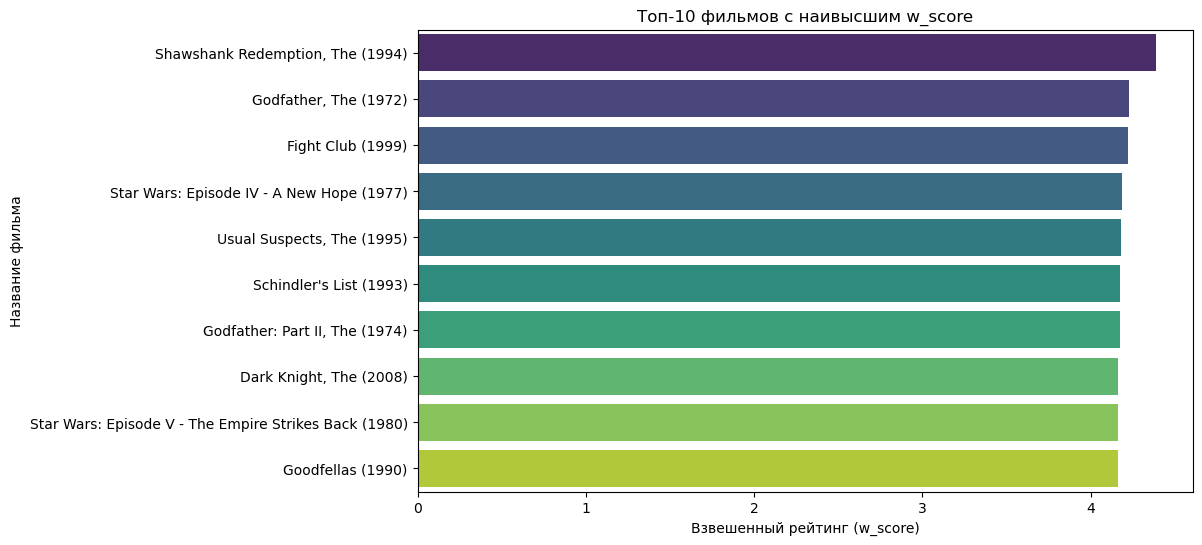

In [4]:
plt.figure(figsize=(10,6))
sns.barplot(x='w_score', y='title', data=top_10_movies, palette='viridis')
plt.xlabel('Взвешенный рейтинг (w_score)')
plt.ylabel('Название фильма')
plt.title('Топ-10 фильмов с наивысшим w_score')
plt.show()

## 3. Коллаборативная фильтрация (Item-based)

Фильтрация на основе контента/объектов исходит из «похожести» объектов. Если пользователь высоко оценил фильм, алгоритм предложит фильмы, которые часто смотрели и высоко оценивали вместе с ним.

Для поиска ближайших соседей используем алгоритм `NearestNeighbors` из scikit-learn с метрикой косинусного сходства (cosine similarity).

In [5]:
pivot = ratings.pivot_table(index='userId', columns='movieId', values='rating').fillna(0)
item_sparse = csr_matrix(pivot.values).T

model_knn_item = NearestNeighbors(metric='cosine', algorithm='brute')
model_knn_item.fit(item_sparse)

NearestNeighbors(algorithm='brute', metric='cosine')

In [6]:
def get_item_based(movie_id, n=10):
    if movie_id not in pivot.columns:
        return []
    item_idx = pivot.columns.get_loc(movie_id)
    # Ищем n+1 соседей, так как самым близким соседом будет сам исходный фильм
    distances, indices = model_knn_item.kneighbors(item_sparse[item_idx], n_neighbors=n+1)
    
    recs = []
    for dist, idx in zip(distances[0][1:], indices[0][1:]):
        rec_id = pivot.columns[idx]
        movie_info = movies[movies['movieId'] == rec_id].iloc[0]
        recs.append({
            'Название': movie_info['title'],
            'Сходство': round(1 - dist, 4)  # Преобразуем дистанцию в меру сходства
        })
    return pd.DataFrame(recs)

get_item_based(1, 10)

,Название,Сходство
0,Toy Story 2 (1999),0.5726
1,Jurassic Park (1993),0.5656
2,Independence Day (a.k.a. ID4) (1996),0.5643
3,Star Wars: Episode IV - A New Hope (1977),0.5574
4,Forrest Gump (1994),0.5471
5,"Lion King, The (1994)",0.5411
6,Star Wars: Episode VI - Return of the Jedi (1983),0.5411
7,Mission: Impossible (1996),0.5389
8,Groundhog Day (1993),0.5342
9,Back to the Future (1985),0.5304


## 4. Коллаборативная фильтрация (User-based)

Этот подход идентифицирует пользователей, похожих на целевого пользователя, на основе их предпочтений, а затем рекомендует элементы, которые понравились этим похожим пользователям. Предполагается, что если пользователи А и В имели схожие предпочтения в прошлом, то то, что нравится одному из них, может понравиться и другому.

In [7]:
user_sparse = csr_matrix(pivot.values)
model_knn_user = NearestNeighbors(metric='cosine', algorithm='brute')
model_knn_user.fit(user_sparse)

NearestNeighbors(algorithm='brute', metric='cosine')

In [8]:
def get_user_based(user_id, n=10):
    if user_id not in pivot.index:
        return []
    user_idx = pivot.index.get_loc(user_id)
    distances, indices = model_knn_user.kneighbors(user_sparse[user_idx], n_neighbors=21)

    # Выбираем похожих пользователей и дистанции до них
    sim_users = indices[0][1:]
    sim_dists = distances[0][1:]
    
    # Взвешенное среднее: чем ближе пользователь, тем больше вес
    weights = 1 / (sim_dists + 1e-9)

    # Оценки похожих пользователей
    sim_ratings = pivot.iloc[sim_users]
    weighted_scores = sim_ratings.T.dot(weights) / weights.sum()

    # Исключаем фильмы, которые уже оценили
    target_ratings = pivot.iloc[user_idx]
    unseen_movies = target_ratings[target_ratings == 0].index
    candidates = weighted_scores.loc[unseen_movies].sort_values(ascending=False).head(n)

    recs = []
    for m_id, score in candidates.items():
        movie_info = movies[movies['movieId'] == m_id].iloc[0]
        recs.append({
            'Название': movie_info['title'],
            'Ожидаемая оценка': round(score, 3)
        })
    return pd.DataFrame(recs)

get_user_based(1, 10)

,Название,Ожидаемая оценка
0,Terminator 2: Judgment Day (1991),3.978
1,Aliens (1986),3.859
2,"Sixth Sense, The (1999)",3.795
3,"Godfather, The (1972)",3.698
4,Jaws (1975),3.684
5,"Breakfast Club, The (1985)",3.492
6,Die Hard (1988),3.455
7,"Hunt for Red October, The (1990)",3.412
8,Ferris Bueller's Day Off (1986),3.169
9,"Christmas Story, A (1983)",3.138


## 5. Контентная фильтрация (TF-IDF)

Фильтрации на знаниях и контенте используют, когда есть точная уверенность в эффективности использования определенного признака или свойства. Мы используем косинусное сходство между векторами жанров, чтобы рекомендовать фильмы с аналогичным распределением.

In [9]:
movies['content_features'] = movies['title'] + " " + movies['genres_clean']

tfidf = TfidfVectorizer(token_pattern=r'(?u)\b[\w-]+\b', stop_words='english')
tfidf_matrix = tfidf.fit_transform(movies['content_features'])

content_sim = cosine_similarity(tfidf_matrix)

In [16]:
def get_content_based_by_title(title_query, n=10):

    matched_movies = movies[movies['title'].str.contains(title_query, case=False, na=False)]
    
    if matched_movies.empty:
        print(f"Фильм по запросу '{title_query}' не найден.")
        return pd.DataFrame()
    
    idx = matched_movies.index[0]
    base_title = matched_movies.iloc[0]['title']
    base_genres = matched_movies.iloc[0]['genres']
    
    print(f"Базовый фильм для рекомендаций: {base_title} | Жанры: {base_genres}")
    print("-" * 50)
    
    scores = list(enumerate(content_sim[idx]))

    scores = sorted(scores, key=lambda x: x[1], reverse=True)[1:n+1]

    recs = []
    for i, score in scores:
        movie_info = movies.iloc[i]
        recs.append({
            'Название': movie_info['title'],
            'Жанры': movie_info['genres'],
            'Косинусное сходство': round(score, 4)
        })
    return pd.DataFrame(recs)

get_content_based_by_title('Toy Story', 10)

Базовый фильм для рекомендаций: Toy Story (1995) | Жанры: Adventure|Animation|Children|Comedy|Fantasy
--------------------------------------------------


,Название,Жанры,Косинусное сходство
0,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.0
1,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
2,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
4,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,1.0
5,"Wild, The (2006)",Adventure|Animation|Children|Comedy|Fantasy,1.0
6,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,1.0
7,"Tale of Despereaux, The (2008)",Adventure|Animation|Children|Comedy|Fantasy,1.0
8,Asterix and the Vikings (Astérix et les Viking...,Adventure|Animation|Children|Comedy|Fantasy,1.0
9,Turbo (2013),Adventure|Animation|Children|Comedy|Fantasy,1.0


# Вывод

В отчете реализованы 4 вида рекомендаций на базе данных movies.csv и ratings.csv:

На основе популярности: Фильтрация с использованием формулы Взвешенного рейтинга IMDb, которая сглаживает оценки. Установлен порог доверия в 80% — для попадания в рейтинг фильм должен набрать больше оценок, чем 80% других фильмов в базе.

Коллаборативная фильтрация: Поиск фильмов на основе оценок пользователей (алгоритм NearestNeighbors). Используется метрика косинусного сходства для нахождения фильмов, которые часто высоко оценивают вместе.

Коллаборативная фильтрация: Персональные рекомендации на основе вкусов похожих пользователей. Алгоритм находит 20 единомышленников, рассчитывает вес их оценок (обратно пропорционально косинусному расстоянию) и прогнозирует рейтинг несмотренных фильмов.

Контентная фильтрация (по жанрам): Использование TfidfVectorizer для перевода текста жанров в векторное пространство и расчет косинусного сходства. Рекомендует фильмы с наиболее похожим распределением жанров